# SIC outcome entropy and stabilizer entropy

The Rényi entropy of a fixed SIC outcome distribution is not generally the
stabilizer entropy. This notebook keeps the two quantities separate, then uses
the operational two-copy WH measurement. Setup is in [Tutorial.ipynb](Tutorial.ipynb).

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import cirq
from pathlib import Path
import tempfile

from cirq_sic.measurements import Measurement, sic_povm, wh_measurement
from cirq_sic.workflow import (
    Experiment, ExperimentResult, tomography_experiment, entropy_experiment,
    wh_entropy_experiment, sky_ground_experiment, triple_product_experiment,
    compile_circuit,
)
from cirq_sic.analysis import stabilizer_renyi_entropy, born_rule_diagnostics
from cirq_sic.triples import triple_products, triple_product_state_space, sic_state_constraints

rng = np.random.default_rng(2026)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
print('Cirq', cirq.__version__)

Cirq 1.3.0


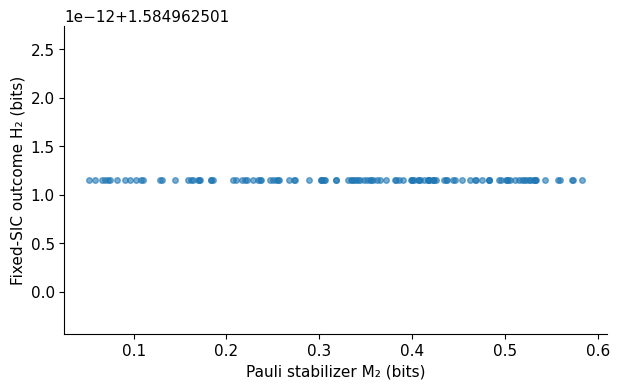

In [2]:
measurement = sic_povm(2)
states = rng.normal(size=(120, 2)) + 1j*rng.normal(size=(120, 2))
states /= np.linalg.norm(states, axis=1, keepdims=True)
stabilizer = np.array([stabilizer_renyi_entropy(s) for s in states])
sic_outcome_entropy = np.array([-np.log2(np.sum(measurement.probabilities(s)**2)) for s in states])
fig, ax = plt.subplots()
ax.scatter(stabilizer, sic_outcome_entropy, s=16, alpha=.6)
ax.set(xlabel='Pauli stabilizer M₂ (bits)', ylabel='Fixed-SIC outcome H₂ (bits)')
plt.show()
# For a pure state measured with a SIC, this collision entropy is constant.
assert np.allclose(sic_outcome_entropy, np.log2(3), atol=1e-8)

## 2. WH entropy, including mixed states

For a cyclic $d$-dimensional WH operator basis, write
$\chi_{ab}=\mathrm{Tr}(\rho D_{ab})$ and $\gamma=\mathrm{Tr}(\rho^2)$.
The purity-corrected Rényi-2 diagnostic is

$$M_2(\rho)=-\log_2\frac{\sum_{ab}|\chi_{ab}|^4}{d\gamma}.$$

A direct two-copy experiment prepares $\rho\otimes\rho^*$ and measures
$s_{ab}=\mathrm{Tr}(\rho D_{ab}\rho D_{ab}^\dagger)/d$.
Discrete Fourier Parseval gives $\gamma=ds_{00}$ and
$M_2=-\log_2(\sum_{ab}s_{ab}^2/s_{00})$. No tomographic inverse is needed.
The ability to prepare the conjugate state is an assumption: this is not a
universal conjugation channel for an unknown input.

For mixed inputs, preparation uses a unitary purification and unmeasured
environment qubits. They are separate from the measurement ancillas.

In [3]:
qubit_sic = sic_povm(2)
magic = qubit_sic.states[:, 0]
rho_magic = np.outer(magic, magic.conj())
rho_mixed = 0.65 * rho_magic + 0.35 * np.eye(2) / 2
entropy_plan = wh_entropy_experiment(rho_mixed)
entropy_exact = entropy_plan.analyze(entropy_plan.simulate())
entropy_sample = entropy_plan.analyze(entropy_plan.run(repetitions=16000, seed=12))
print('Purity (exact / sampled):', entropy_exact['purity'], entropy_sample['purity'])
print('M2 (exact / sampled):', entropy_exact['entropy'], entropy_sample['entropy'])
assert np.isclose(entropy_exact['entropy'],
                  stabilizer_renyi_entropy(rho_mixed, basis='wh', mixed=True))

Purity (exact / sampled): 0.7112500000000004 0.71625
M2 (exact / sampled): 0.4250422280009031 0.43121339171959205


The mixed-state extension is a diagnostic, not a faithful magic measure on
the convex hull of stabilizer states. Even $\rho=\mathrm{diag}(0.75,0.25)$ has
positive $M_2$. Finite-shot collision probabilities, ratios, and logarithms are
biased; a small negative estimate is not clipped to zero. If the identity
outcome is never observed, the ratio cannot be estimated and analysis raises.

`basis='pauli'` means tensor-product qubit Paulis. `basis='wh'` means one cyclic
qudit. They agree for a single qubit but differ for $d\ge4$; embedding a qudit in
qubits does not change which operator basis defines your diagnostic.
`entropy_experiment` supplies a complementary route: measure an IC POVM,
reconstruct the state, then evaluate a chosen Rényi order and basis. For sampled
or mixed inputs use `mixed=True` and inspect the reconstruction/projection.